# Supplementary Figure 5: COSMIC CMC benchmark AUROC

1. Load the pre-merged table `cosmic/cosmic_cmc_benchmark_all_with_scores.csv` (no per-tool merge in this notebook).
2. Rebuild **only the ClinVar-style fixed subgroup grid** from scratch (drop any stale `group: ...` columns first). Names use display-style capitalization and `&`: e.g. `group: Coding`, `group: Noncoding`, `group: Missense & 3'UTR`.
3. **`group: Noncoding`** follows the ClinVar logic: it is the complement of coding sequence. In COSMIC this is `coding_sequence == 0` because COSMIC has a single coding flag.
4. **`Rule_based`**: cohort **driver prevalence** by an internal raw consequence category (`subgroup` + `mut_type_raw` + active annotation flags). This is a type-prevalence baseline, not a learned model.
5. **AUROC** = point estimate only (**no bootstrap CI** in this notebook).
6. Subgroups with **minority class < 20** cannot have AUROC values, but their columns and counts remain in the CSV/plot order.
7. **Rule-based AUROC** is computed only for **`Overall`** and **`group: Noncoding`** when mathematically possible.

8. **Earlier multi-panel PDFs** with dozens of `group: …` columns came from enumerating many COSMIC-specific slices; this notebook now uses **only the fixed ClinVar-style grid** so consequence definitions stay comparable to ClinVar.


## 1. Load merged dataset and subgroup columns

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


COSMIC_DIR = Path("cosmic")
# Score matrix supplied by the authors on 2026-09-09. Unlike the earlier merged file it
# carries GPN-Star, VESM++ and the NTv3 heads, and drops the superseded NT v2 column,
# restoring the full 17-predictor panel shown in the submitted figure.
MERGED_PATH = COSMIC_DIR / "cosmic_all_scores.csv"

# Same subgroup grid as ClinVar_RefSeq, with display-style names requested here:
# first token capitalized and compound terms joined by " & ".
CLINVAR_STYLE_GROUPS = [
    "group: Coding",
    "group: Noncoding",
    "group: Start loss",
    "group: Start loss & 3'UTR",
    "group: Start loss & 5'UTR",
    "group: Start loss & Intron (non-splice)",
    "group: Missense",
    "group: Missense & 3'UTR",
    "group: Missense & 5'UTR",
    "group: Missense & Intron (non-splice)",
    "group: Synonymous",
    "group: Synonymous & 3'UTR",
    "group: Synonymous & 5'UTR",
    "group: Synonymous & Intron (non-splice)",
    "group: Stop gain",
    "group: Stop gain & 3'UTR",
    "group: Stop gain & 5'UTR",
    "group: Stop gain & Intron (non-splice)",
    "group: Stop loss",
    "group: Stop loss & 3'UTR",
    "group: Stop loss & 5'UTR",
    "group: Stop synonymous",
    "group: Stop synonymous & 3'UTR",
    "group: 5'UTR",
    "group: 5'UTR & 3'UTR",
    "group: 5'UTR & Intron (non-splice)",
    "group: 5'UTR & Splice",
    "group: 3'UTR",
    "group: 3'UTR & Intron (non-splice)",
    "group: 3'UTR & Splice",
    "group: 3'UTR & RNA gene",
    "group: Splice",
    "group: Intron (non-splice)",
    "group: Intron (non-splice) & RNA gene",
    "group: RNA gene",
]


def _bool_col(d: pd.DataFrame, col: str) -> pd.Series:
    """Treat missing annotation columns as all-False so the ClinVar grid is stable."""
    if col not in d.columns:
        return pd.Series(False, index=d.index)
    return d[col].fillna(0).astype(int).eq(1)


def add_clinvar_style_subgroup_columns(d: pd.DataFrame) -> pd.DataFrame:
    """Recreate the ClinVar_RefSeq subgroup logic on COSMIC annotation columns.

    ClinVar uses: Coding = coding-sequence; Noncoding = not coding-sequence.  COSMIC has one
    coding flag, so the equivalent is ``coding_sequence == 1`` and ``coding_sequence == 0``.
    The remaining masks follow the ClinVar fixed consequence grid and are not raw cohort buckets.
    """
    d = d.copy()

    coding = _bool_col(d, "coding_sequence")
    start = _bool_col(d, "start_codon")
    u5 = _bool_col(d, "five_prime_UTR")
    u3 = _bool_col(d, "three_prime_UTR")
    intr = _bool_col(d, "mRNA_intron")
    splice = _bool_col(d, "mRNA_splice")

    rna_prefixes = ("lncRNA", "snRNA", "snoRNA", "antisenseRNA", "telomeraseRNA", "RNaseMRPRNA")
    rna_cols = [
        c for c in d.columns
        if c.startswith(rna_prefixes) and not c.endswith("_promoter")
    ]
    rna_gene = d[rna_cols].fillna(0).astype(int).eq(1).any(axis=1) if rna_cols else pd.Series(False, index=d.index)

    missense = d["subgroup"].astype(str).eq("missense")
    synonymous = d["subgroup"].astype(str).eq("synonymous")
    stop_gain = d["subgroup"].astype(str).eq("stop_gain")

    # COSMIC CMC does not provide a stop-loss / stop-synonymous subgroup comparable to ClinVar's
    # Union_stop_loss, so these ClinVar-grid columns are present but all zero.
    stop_loss = pd.Series(False, index=d.index)

    d[CLINVAR_STYLE_GROUPS] = 0

    d["group: Coding"] = coding.astype(int)
    d["group: Noncoding"] = (~coding).astype(int)

    d["group: Start loss"] = (start & ~u5 & ~u3 & ~intr).astype(int)
    d["group: Start loss & 3'UTR"] = (start & ~u5 & u3 & ~intr).astype(int)
    d["group: Start loss & 5'UTR"] = (start & u5 & ~u3 & ~intr).astype(int)
    d["group: Start loss & Intron (non-splice)"] = (start & ~u5 & ~u3 & intr).astype(int)

    d["group: Missense"] = (~start & missense & ~u5 & ~u3 & ~intr).astype(int)
    d["group: Missense & 3'UTR"] = (~start & missense & ~u5 & u3 & ~intr).astype(int)
    d["group: Missense & 5'UTR"] = (~start & missense & u5 & ~u3 & ~intr).astype(int)
    d["group: Missense & Intron (non-splice)"] = (~start & missense & ~u5 & ~u3 & intr).astype(int)

    d["group: Synonymous"] = (synonymous & ~u5 & ~u3 & ~intr & ~stop_loss).astype(int)
    d["group: Synonymous & 3'UTR"] = (synonymous & ~u5 & u3 & ~intr & ~stop_loss).astype(int)
    d["group: Synonymous & 5'UTR"] = (synonymous & u5 & ~u3 & ~intr & ~stop_loss).astype(int)
    d["group: Synonymous & Intron (non-splice)"] = (synonymous & ~u5 & ~u3 & intr & ~stop_loss).astype(int)

    d["group: Stop synonymous"] = (synonymous & ~u5 & ~u3 & ~intr & stop_loss).astype(int)
    d["group: Stop synonymous & 3'UTR"] = (synonymous & ~u5 & u3 & ~intr & stop_loss).astype(int)

    d["group: Stop gain"] = (stop_gain & ~u5 & ~u3 & ~intr).astype(int)
    d["group: Stop gain & 3'UTR"] = (stop_gain & ~u5 & u3 & ~intr).astype(int)
    d["group: Stop gain & 5'UTR"] = (stop_gain & u5 & ~u3 & ~intr).astype(int)
    d["group: Stop gain & Intron (non-splice)"] = (stop_gain & ~u5 & ~u3 & intr).astype(int)

    d["group: Stop loss"] = (~synonymous & stop_loss & ~u5 & ~u3 & ~intr).astype(int)
    d["group: Stop loss & 3'UTR"] = (~synonymous & stop_loss & ~u5 & u3 & ~intr).astype(int)
    d["group: Stop loss & 5'UTR"] = (~synonymous & stop_loss & u5 & ~u3 & ~intr).astype(int)

    no_primary = ~start & ~missense & ~synonymous & ~stop_gain & ~stop_loss
    d["group: 5'UTR"] = (no_primary & u5 & ~u3 & ~splice & ~intr).astype(int)
    d["group: 5'UTR & 3'UTR"] = (no_primary & u5 & u3 & ~splice & ~intr).astype(int)
    d["group: 5'UTR & Intron (non-splice)"] = (no_primary & u5 & ~u3 & ~splice & intr).astype(int)
    d["group: 5'UTR & Splice"] = (no_primary & u5 & ~u3 & splice & intr).astype(int)

    d["group: 3'UTR"] = (no_primary & ~u5 & u3 & ~splice & ~intr & ~rna_gene).astype(int)
    d["group: 3'UTR & Intron (non-splice)"] = (no_primary & ~u5 & u3 & ~splice & intr & ~rna_gene).astype(int)
    d["group: 3'UTR & Splice"] = (no_primary & ~u5 & u3 & splice & intr & ~rna_gene).astype(int)
    d["group: 3'UTR & RNA gene"] = (no_primary & ~u5 & u3 & ~splice & ~intr & rna_gene).astype(int)

    d["group: Splice"] = (no_primary & ~u5 & ~u3 & splice & intr & ~rna_gene).astype(int)
    d["group: Intron (non-splice)"] = (no_primary & ~u5 & ~u3 & ~splice & intr & ~rna_gene).astype(int)
    d["group: Intron (non-splice) & RNA gene"] = (no_primary & ~u5 & ~u3 & ~splice & intr & rna_gene).astype(int)
    d["group: RNA gene"] = (no_primary & ~u5 & ~u3 & ~splice & ~intr & rna_gene).astype(int)

    return d


ANN_FLAGS_FOR_RULE = [
    "coding_sequence",
    "five_prime_UTR",
    "three_prime_UTR",
    "mRNA_intron",
    "mRNA_splice",
    "start_codon",
    "stop_codon",
]


def build_cosmic_consequence_category(df: pd.DataFrame) -> pd.Series:
    """Stable internal key for Rule_based prevalence; not used as displayed subgroup names."""

    def _sig_row(r) -> str:
        on = [c for c in ANN_FLAGS_FOR_RULE if c in df.columns and int(r[c]) == 1]
        return "+".join(on) if on else "ann:none"

    sig = df[ANN_FLAGS_FOR_RULE].apply(_sig_row, axis=1)
    return df["subgroup"].astype(str) + " | " + df["mut_type_raw"].astype(str) + " | " + sig.astype(str)


main = pd.read_csv(MERGED_PATH, low_memory=False)
main["#CHROM"] = main["#CHROM"].astype(str).str.replace("^chr", "", regex=True)
print("merged dataset:", MERGED_PATH, main.shape)

# Always rebuild the group columns from scratch so stale lowercase / obs_* / cohort_* names cannot hide the new logic.
_old_groups = [c for c in main.columns if c.startswith("group: ")]
main = main.drop(columns=_old_groups, errors="ignore")
main = add_clinvar_style_subgroup_columns(main)

main = main.drop(columns=["Rule_based", "_cosmic_cat"], errors="ignore")
main["_cosmic_cat"] = build_cosmic_consequence_category(main)
main["Rule_based"] = main.groupby("_cosmic_cat", dropna=False)["label"].transform("mean")

rb_map = (
    main.groupby("_cosmic_cat", dropna=False)
    .agg(n_variants=("label", "size"), driver_prevalence=("label", "mean"))
    .reset_index()
    .sort_values("driver_prevalence")
)
rb_map.to_csv(COSMIC_DIR / "cosmic_rule_based_prevalence_by_category.csv", index=False)

print(f"\nClinVar-style `group:` slices: {len(CLINVAR_STYLE_GROUPS)}")
print("\nAll ClinVar-style group counts:")
for g in CLINVAR_STYLE_GROUPS:
    sub = main.loc[main[g] == 1, "label"]
    n = len(sub)
    pos = int(sub.sum()) if n else 0
    neg = n - pos
    print(f"  {g}: n={n} pos={pos} neg={neg} min_minority={min(pos, neg) if n else 0}")

print("\n(On-disk merged CSV unchanged; Rule_based / _cosmic_cat recomputed in memory.)")
print("wrote", COSMIC_DIR / "cosmic_rule_based_prevalence_by_category.csv")
main.head()


merged dataset: cosmic/cosmic_all_scores.csv (55538, 67)



ClinVar-style `group:` slices: 35

All ClinVar-style group counts:
  group: Coding: n=54417 pos=2113 neg=52304 min_minority=2113
  group: Noncoding: n=1121 pos=0 neg=1121 min_minority=0
  group: Start loss: n=8 pos=2 neg=6 min_minority=2
  group: Start loss & 3'UTR: n=0 pos=0 neg=0 min_minority=0
  group: Start loss & 5'UTR: n=0 pos=0 neg=0 min_minority=0
  group: Start loss & Intron (non-splice): n=0 pos=0 neg=0 min_minority=0
  group: Missense: n=51036 pos=230 neg=50806 min_minority=230
  group: Missense & 3'UTR: n=246 pos=10 neg=236 min_minority=10
  group: Missense & 5'UTR: n=94 pos=0 neg=94 min_minority=0
  group: Missense & Intron (non-splice): n=1118 pos=0 neg=1118 min_minority=0
  group: Synonymous: n=0 pos=0 neg=0 min_minority=0
  group: Synonymous & 3'UTR: n=2 pos=0 neg=2 min_minority=0
  group: Synonymous & 5'UTR: n=4 pos=0 neg=4 min_minority=0
  group: Synonymous & Intron (non-splice): n=0 pos=0 neg=0 min_minority=0
  group: Stop gain: n=2942 pos=1863 neg=1079 min_minority

,#CHROM,POS,REF,ALT,gene,label,label_source,subgroup,cmc_tier,af_bin,...,group: 3'UTR,group: 3'UTR & Intron (non-splice),group: 3'UTR & Splice,group: 3'UTR & RNA gene,group: Splice,group: Intron (non-splice),group: Intron (non-splice) & RNA gene,group: RNA gene,_cosmic_cat,Rule_based
0,1,69496,G,A,1,0,CMC_TierOther_stratified,missense,Other,rare,...,0,0,0,0,0,0,0,0,missense | SO:0001583 | coding_sequence,0.004817
1,1,69511,A,G,1,0,CMC_TierOther_stratified,missense,Other,common,...,0,0,0,0,0,0,0,0,missense | SO:0001583 | coding_sequence,0.004817
2,1,930204,G,A,1,0,CMC_TierOther_stratified,missense,Other,rare,...,0,0,0,0,0,0,0,0,missense | SO:0001583 | coding_sequence,0.004817
3,1,930285,G,A,1,0,CMC_TierOther_stratified,missense,Other,very_rare,...,0,0,0,0,0,0,0,0,missense | SO:0001583 | coding_sequence,0.004817
4,1,930314,C,T,1,0,CMC_TierOther_stratified,missense,Other,low_freq,...,0,0,0,0,0,0,0,0,missense | SO:0001583 | coding_sequence,0.004817


## 2. AUROC (point estimates; **no CI**)

Rule-based AUROC only where noted; all other tools evaluated in every subgroup that passes the **minority ≥ 20** rule.

In [2]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

data = main

MINORITY_MIN = 20

# Only these panels get a Rule-based AUROC bar (ClinVar convention); still need ≥2 categories inside the slice.
RULE_BASED_AUROC_GROUPS = frozenset({"Overall", "group: Noncoding"})

# Complete-case AUROC uses rows where *all* listed scores are non-missing.
# Protein LM / AlphaMissense / PrimateAI-3D are often blank outside missense-like slices, so N drops vs DNA-only.
TOOLS = [
    "PhyloP",
    "Evo2_40b_Var_minus_Ref",
    "Evo2_7b_Var_minus_Ref",
    "AlphaGenome_raw_abs",
    "GPN_MSA_score",
    "PhyloGPN",
    "gpnstar_v_llr",
    "DB2",
    "ntv3_pre_position_llr",
    "ntv3_post_log2fc_max",
    "ESM1b_score",
    "ESM1v-1_score",
    "ESM2_score",
    "vesm_score",
    "am_score",
    "pai_score",
    "Rule_based",
]

# Align with ClinVar / VEP conventions: higher score ⇒ more pathogenic-like (no 1−AUROC flip).
# ESM / Evo2 log-likelihood-style scores use 1−AUROC (same as `cosmic/COSMIC_AUROC.ipynb`).
# Scores whose raw orientation is already "higher = more driver-like".
# Note ntv3_pre_position_llr: this COSMIC matrix stores it with the opposite sign convention
# to the ClinVar benchmark, where the same column must be negated. Verified against the
# submitted figure, which reports NTv3-pre = 0.866 on all variants (the negated orientation
# would give 0.134, i.e. strongly anti-predictive, which is not credible).
NO_FLIP_TOOLS = {
    "PhyloP",
    "DB2",
    "AlphaGenome_raw_abs",
    "Rule_based",
    "am_score",
    "pai_score",
    "ntv3_post_log2fc_max",
    "ntv3_pre_position_llr",
}

SUBGROUP_COLS = sorted([c for c in data.columns if c.startswith("group: ")])
groups = ["Overall"] + SUBGROUP_COLS

label_col = "label"

results = {g: {} for g in groups}
results_ci_low = {g: {} for g in groups}
results_ci_high = {g: {} for g in groups}

common_mask = data[TOOLS].notna().all(axis=1)


# Confidence intervals use the same procedure as Figure 1 and Supplementary Figures 2-4:
# 1,000 stratified bootstrap resamples of variants, drawing each class separately to its
# observed size, with the interval given by the 2.5th and 97.5th percentiles. The measure
# of centre is the AUROC on the complete observed data.
N_BOOTSTRAPS = 1_000


def bootstrap_auc_ci(y, s, n_boot=N_BOOTSTRAPS, seed=42):
    y = np.asarray(y).astype(float)
    s = np.asarray(s).astype(float)
    valid = np.isfinite(y) & np.isfinite(s)
    y = y[valid].astype(int)
    s = s[valid]
    if len(y) == 0 or np.unique(y).size < 2:
        return np.nan, np.nan, np.nan
    auc_hat = roc_auc_score(y, s)
    rng = np.random.default_rng(seed)
    class_indices = [np.flatnonzero(y == label) for label in (0, 1)]
    aucs = []
    for _ in range(n_boot):
        idx = np.concatenate([
            rng.choice(indices, size=len(indices), replace=True)
            for indices in class_indices
        ])
        aucs.append(roc_auc_score(y[idx], s[idx]))
    low, high = np.percentile(aucs, [2.5, 97.5])
    return float(auc_hat), float(low), float(high)


def minority_ok(y):
    y = np.asarray(y).astype(int)
    if len(y) == 0 or np.unique(y).size < 2:
        return False
    pos = int(y.sum())
    neg = len(y) - pos
    return min(pos, neg) >= MINORITY_MIN


eligible_subgroups = set()
for sk in SUBGROUP_COLS:
    sub = data.loc[common_mask & (data[sk] == 1), label_col]
    if minority_ok(sub.values):
        eligible_subgroups.add(sk)

print("Subgroups with minority ≥", MINORITY_MIN, ":", sorted(eligible_subgroups))


def _blank_group_outcome(group):
    for tool in TOOLS:
        results[group][tool] = ""
        results_ci_low[group][tool] = ""
        results_ci_high[group][tool] = ""


def sanitize_auc(auc):
    if auc is None or np.isnan(auc):
        return ""
    return round(float(auc), 4)


plot_manifest = []

for group in tqdm(groups, desc="AUC by group"):
    if group == "Overall":
        subset = data.loc[common_mask]
    else:
        if group not in eligible_subgroups:
            n = int((common_mask & (data[group] == 1)).sum())
            n_pos = int(data.loc[common_mask & (data[group] == 1), label_col].sum())
            _blank_group_outcome(group)
            results[group]["#Variants"] = n
            results_ci_low[group]["#Variants"] = ""
            results_ci_high[group]["#Variants"] = ""
            results[group]["p%"] = round(100 * n_pos / n, 2) if n else ""
            results_ci_low[group]["p%"] = ""
            results_ci_high[group]["p%"] = ""
            continue
        subset = data.loc[common_mask & (data[group] == 1)]

    n = len(subset)
    n_pos = int(subset[label_col].sum()) if n else 0
    n_cat = int(subset["_cosmic_cat"].nunique())
    n_rb = int(subset["Rule_based"].nunique(dropna=True))

    for tool in TOOLS:
        if subset[label_col].nunique() < 2 or n == 0:
            results[group][tool] = ""
            results_ci_low[group][tool] = ""
            results_ci_high[group][tool] = ""
            continue

        if tool == "Rule_based":
            if group not in RULE_BASED_AUROC_GROUPS:
                results[group][tool] = ""
                results_ci_low[group][tool] = ""
                results_ci_high[group][tool] = ""
                continue
            if n_cat < 2 or n_rb < 2:
                results[group][tool] = ""
                results_ci_low[group][tool] = ""
                results_ci_high[group][tool] = ""
                continue

        # Sign-flipping is applied to the score rather than to the AUROC, so the
        # bootstrap interval is computed on the same orientation that is plotted.
        scores = subset[tool].to_numpy(dtype=float)
        if tool not in NO_FLIP_TOOLS:
            scores = -scores
        auc, ci_low, ci_high = bootstrap_auc_ci(subset[label_col].to_numpy(), scores)
        results[group][tool] = sanitize_auc(auc)
        results_ci_low[group][tool] = sanitize_auc(ci_low)
        results_ci_high[group][tool] = sanitize_auc(ci_high)

    results[group]["#Variants"] = n
    results_ci_low[group]["#Variants"] = ""
    results_ci_high[group]["#Variants"] = ""
    results[group]["p%"] = round(100 * n_pos / n, 2) if n else ""
    results_ci_low[group]["p%"] = ""
    results_ci_high[group]["p%"] = ""

    if group == "Overall" or group in eligible_subgroups:
        plot_manifest.append(
            {
                "raw_key": group,
                "N": n,
                "n_pos": n_pos,
                "pct_pathogenic": round(100 * n_pos / n, 4) if n else 0.0,
                "n_unique_cosmic_cat": n_cat,
                "n_unique_rule_based": n_rb,
            }
        )

audit_rows = []
manifest_df = pd.DataFrame(plot_manifest)

INTRON_KEY = "group: Missense & Intron (non-splice)"
if INTRON_KEY in data.columns:
    hit = data.loc[common_mask & (data[INTRON_KEY] == 1)]
    print("\n=== Legacy-style audit:", INTRON_KEY, "===")
    print("N (complete-case & intron slice):", len(hit))
    if len(hit):
        print("subgroup × mut_type_raw counts:\n", hit.groupby(["subgroup", "mut_type_raw"]).size().to_string())
        print("n _cosmic_cat:", hit["_cosmic_cat"].nunique())
        print("Rule_based unique (new def):", hit["Rule_based"].nunique())
        vc = hit["_cosmic_cat"].value_counts()
        print("Top _cosmic_cat:\n", vc.head(15).to_string())
        cat_prev = hit.groupby("_cosmic_cat")["Rule_based"].first()
        if cat_prev.nunique() > 1:
            print("Category → Rule_based (first):\n", cat_prev.sort_values().to_string())
        print(
            "Interpretation of old ~0.993 Rule AUROC: the slice mixes multiple "
            "`_cosmic_cat` rows (e.g. different SO terms / flag combos). Rule_based "
            "then takes different prevalence values → a finite AUC. Not a merge/plot "
            "bug; it is **not** 'type-only' within a single consequence category."
        )

print("\n=== Per-panel sanity (plotted / eligible slices) ===")
for _, row in manifest_df.iterrows():
    raw = row["raw_key"]
    if raw == "Overall":
        m = common_mask
    else:
        m = common_mask & (data[raw] == 1)
    sub = data.loc[m]
    n_c = int(sub["_cosmic_cat"].nunique())
    n_r = int(sub["Rule_based"].nunique(dropna=True))
    print(
        f"{raw}: N={len(sub)} n_cat={n_c} n_rule_scores={n_r}",
    )
    if n_r > 1:
        mp = sub.groupby("_cosmic_cat")["Rule_based"].first().sort_values()
        print(mp.to_string())
        print("---")

manifest_df.to_csv(COSMIC_DIR / "cosmic_plot_panel_audit.csv", index=False)
print("\nWrote", COSMIC_DIR / "cosmic_plot_panel_audit.csv")

row_order = TOOLS + ["#Variants", "p%"]
result_df = pd.DataFrame(results).loc[row_order]
result_low = pd.DataFrame(results_ci_low).loc[row_order]
result_high = pd.DataFrame(results_ci_high).loc[row_order]

result_df.to_csv(COSMIC_DIR / "cosmic_auc_result.csv")
result_low.to_csv(COSMIC_DIR / "cosmic_auc_result_ci_low.csv")
result_high.to_csv(COSMIC_DIR / "cosmic_auc_result_ci_high.csv")

plot_keys = []
if minority_ok(data.loc[common_mask, label_col].values):
    plot_keys.append("Overall")
clinvar_order_tail = CLINVAR_STYLE_GROUPS.copy()
for k in clinvar_order_tail:
    if k in data.columns and k not in plot_keys:
        plot_keys.append(k)
for k in sorted(eligible_subgroups):
    if k not in plot_keys:
        plot_keys.append(k)

pd.Series(plot_keys, name="plot_order_raw").to_csv(COSMIC_DIR / "cosmic_figure_plot_order.csv", index=False)
print("Wrote", COSMIC_DIR / "cosmic_figure_plot_order.csv")

result_df




Subgroups with minority ≥ 20 : ['group: Coding', 'group: Missense', 'group: Stop gain']


AUC by group:   0%|          | 0/36 [00:00<?, ?it/s]

AUC by group:   3%|▎         | 1/36 [02:10<1:16:03, 130.40s/it]

AUC by group:  28%|██▊       | 10/36 [04:13<09:35, 22.13s/it]  

AUC by group:  36%|███▌      | 13/36 [06:09<10:24, 27.15s/it]

AUC by group:  67%|██████▋   | 24/36 [06:18<02:11, 10.93s/it]

AUC by group: 100%|██████████| 36/36 [06:18<00:00, 10.51s/it]


=== Legacy-style audit: group: Missense & Intron (non-splice) ===
N (complete-case & intron slice): 669
subgroup × mut_type_raw counts:
 subgroup  mut_type_raw
missense  SO:0001583      669
n _cosmic_cat: 2
Rule_based unique (new def): 1
Top _cosmic_cat:
 _cosmic_cat
missense | SO:0001583 | coding_sequence+mRNA_intron    630
missense | SO:0001583 | mRNA_intron                     39
Interpretation of old ~0.993 Rule AUROC: the slice mixes multiple `_cosmic_cat` rows (e.g. different SO terms / flag combos). Rule_based then takes different prevalence values → a finite AUC. Not a merge/plot bug; it is **not** 'type-only' within a single consequence category.

=== Per-panel sanity (plotted / eligible slices) ===
Overall: N=39548 n_cat=15 n_rule_scores=6
_cosmic_cat
missense | SO:0001583 | ann:none                            0.000000
missense | SO:0001583 | coding_sequence+five_prime_UTR      0.000000
missense | SO:0001583 | coding_sequence+mRNA_intron         0.000000
missense | SO:000158

,Overall,group: 3'UTR,group: 3'UTR & Intron (non-splice),group: 3'UTR & RNA gene,group: 3'UTR & Splice,group: 5'UTR,group: 5'UTR & 3'UTR,group: 5'UTR & Intron (non-splice),group: 5'UTR & Splice,group: Coding,...,group: Stop gain & Intron (non-splice),group: Stop loss,group: Stop loss & 3'UTR,group: Stop loss & 5'UTR,group: Stop synonymous,group: Stop synonymous & 3'UTR,group: Synonymous,group: Synonymous & 3'UTR,group: Synonymous & 5'UTR,group: Synonymous & Intron (non-splice)
PhyloP,0.7416,,,,,,,,,0.7413,...,,,,,,,,,,
Evo2_40b_Var_minus_Ref,0.8825,,,,,,,,,0.8824,...,,,,,,,,,,
Evo2_7b_Var_minus_Ref,0.9010,,,,,,,,,0.9008,...,,,,,,,,,,
AlphaGenome_raw_abs,0.6925,,,,,,,,,0.6926,...,,,,,,,,,,
GPN_MSA_score,0.8635,,,,,,,,,0.8633,...,,,,,,,,,,
PhyloGPN,0.8210,,,,,,,,,0.8207,...,,,,,,,,,,
gpnstar_v_llr,0.9074,,,,,,,,,0.9073,...,,,,,,,,,,
DB2,0.4342,,,,,,,,,0.4343,...,,,,,,,,,,
ntv3_pre_position_llr,0.8660,,,,,,,,,0.8659,...,,,,,,,,,,
ntv3_post_log2fc_max,0.6674,,,,,,,,,0.6674,...,,,,,,,,,,


## 3. Plot (ClinVar-style panels; no CI whiskers)

Optional priority order from `cosmic/cosmic_figure_plot_order.csv` (written when you run the AUROC cell). Any subgroup columns in `cosmic_auc_result.csv` that have at least one AUROC value but are missing from that file are **appended** (so an old short CSV cannot hide panels).

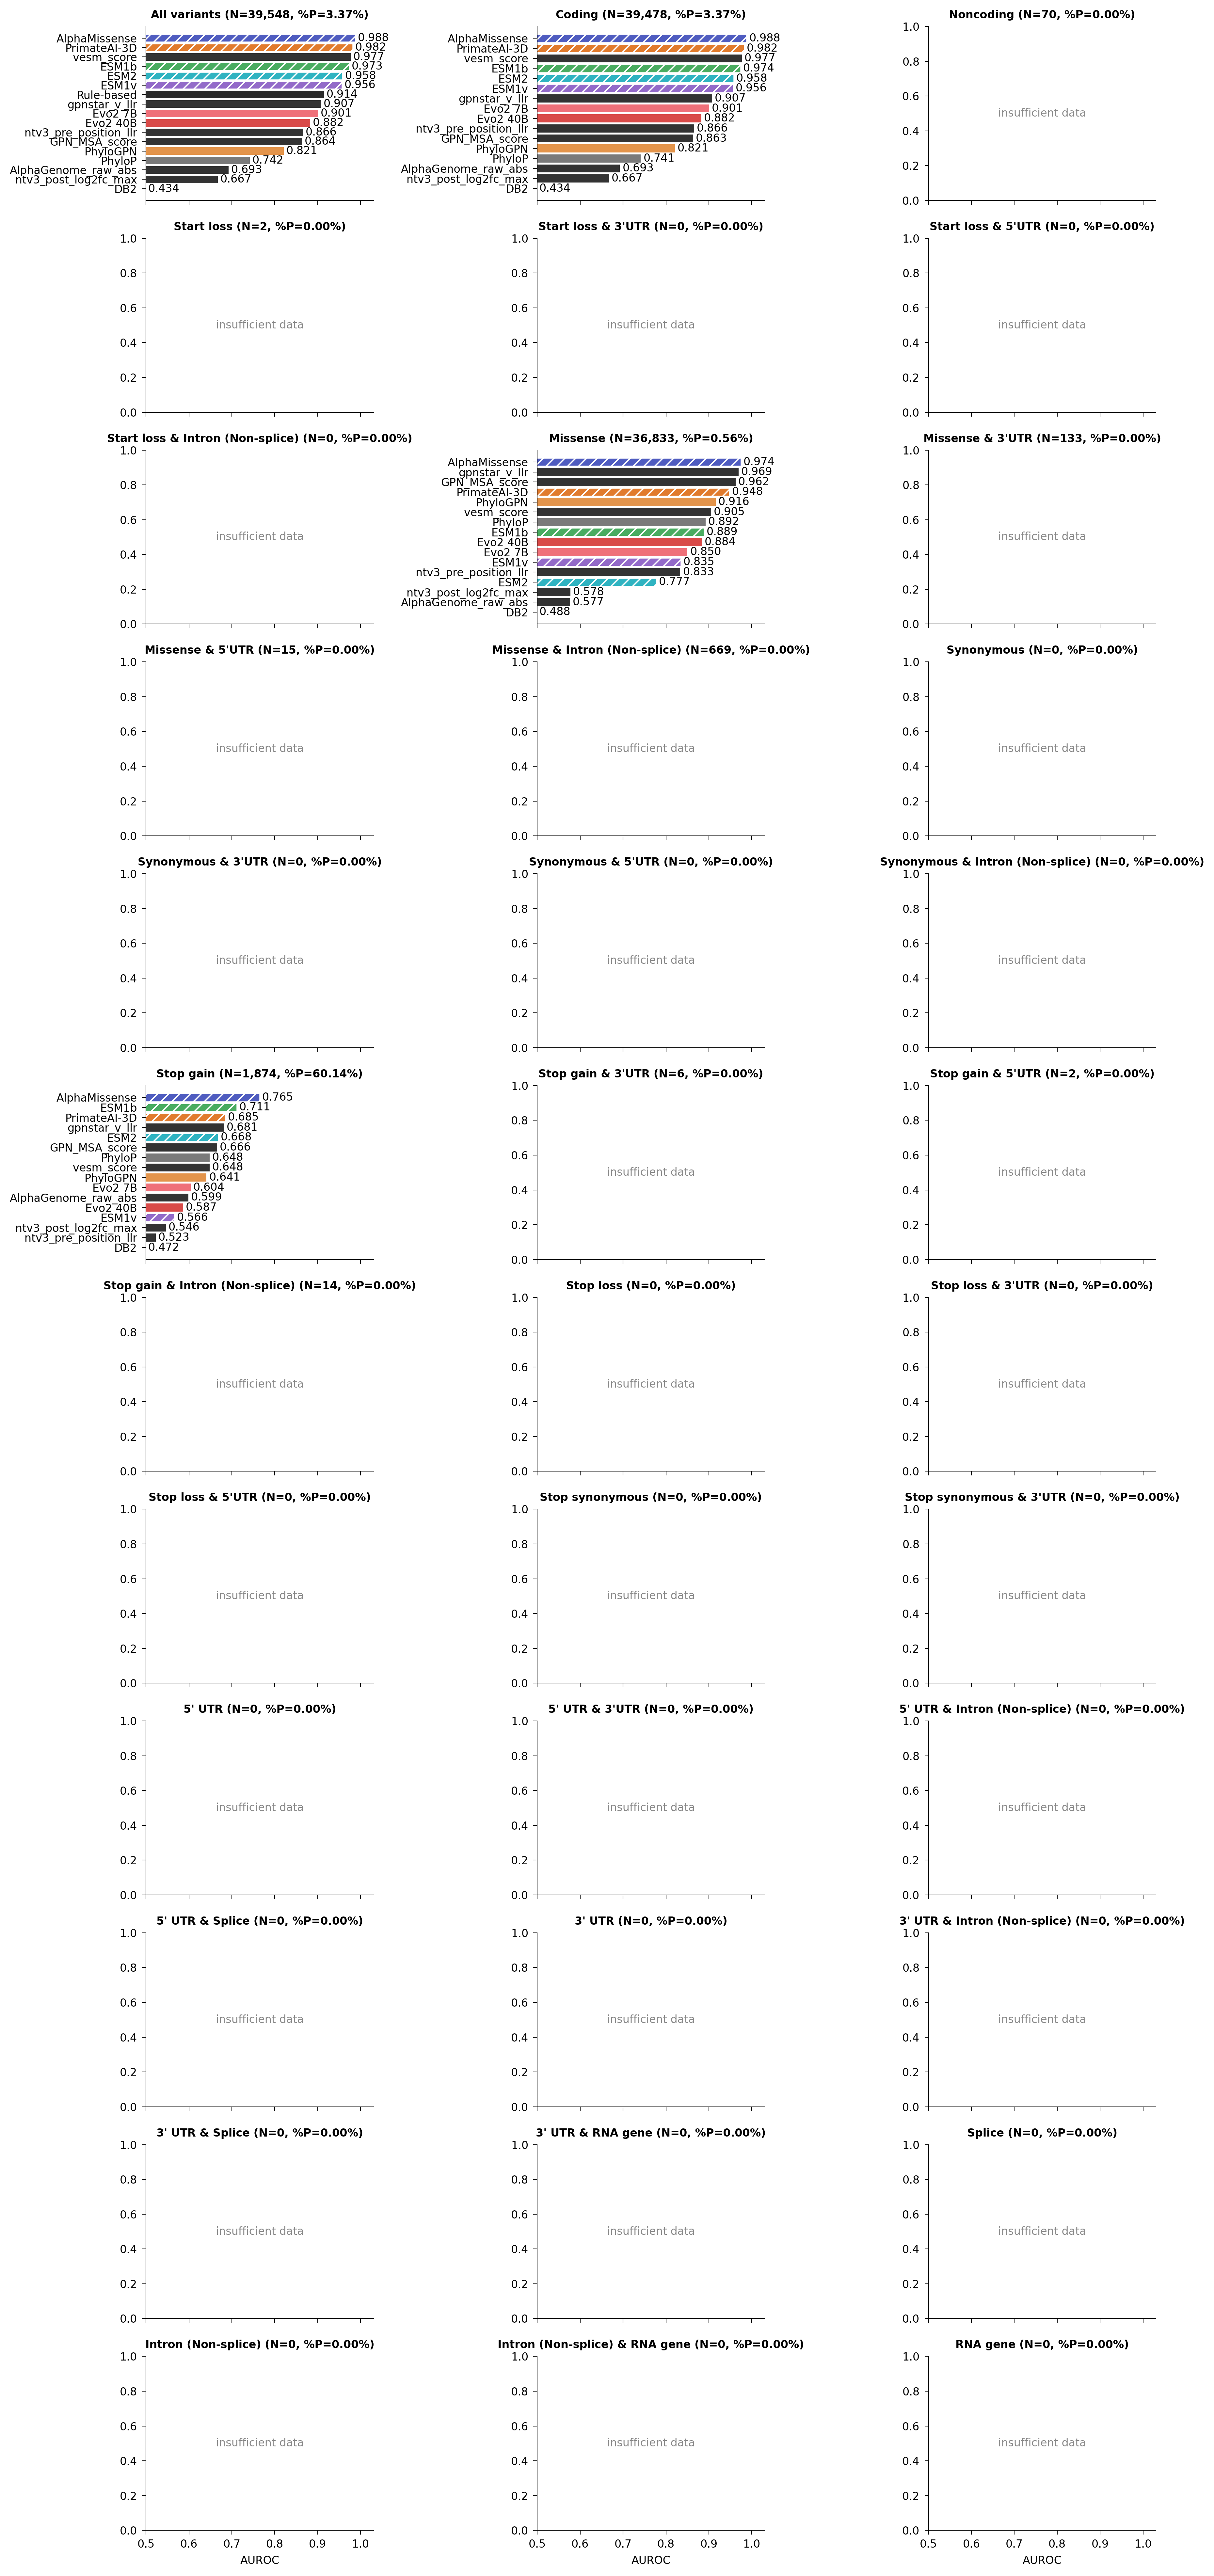

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from collections import defaultdict

FONT_SIZE = 8
FONT_NAME = "DejaVu Sans"
SAVE_BIG = True

df = pd.read_csv(COSMIC_DIR / "cosmic_auc_result.csv")

rename_dict = {
    "DNABERT2": "DNABERT2",
    "Nucleotide_Transformer": "Nucleotide Transformer",
    "PhyloP": "PhyloP",
    "Evo2_40b_Var_minus_Ref": "Evo2 40B",
    "Evo2_7b_Var_minus_Ref": "Evo2 7B",
    "AlphaGenome_raw": "AlphaGenome",
    "GPN_MSA": "GPN-MSA",
    "PhyloGPN": "PhyloGPN",
    "Rule_based": "Rule-based",
    "ESM1b_score": "ESM1b",
    "ESM1v-1_score": "ESM1v",
    "ESM2_score": "ESM2",
    "am_score": "AlphaMissense",
    "pai_score": "PrimateAI-3D",
}

df = df.rename(columns=rename_dict)
df["Unnamed: 0"] = df["Unnamed: 0"].replace(rename_dict)

palette = {
    "DNABERT2": "#9F3C51",
    "Nucleotide Transformer": "#936AC9",
    "PhyloP": "#7A7A7A",
    "Evo2 40B": "#D94A48",
    "Evo2 7B": "#EF7079",
    "GPN-MSA": "#758FD4",
    "PhyloGPN": "#E3944B",
    "AlphaGenome": "#8FCB3F",
    "Rule-based": "#2B2B2B",
    "ESM1b": "#49AC60",
    "ESM1v": "#936AC9",
    "ESM2": "#2FB3C1",
    "AlphaMissense": "#4F5CC0",
    "PrimateAI-3D": "#E17B2D",
}
dashed_models = {"ESM1b", "ESM1v", "ESM2", "AlphaMissense", "PrimateAI-3D"}

model_rows = df["Unnamed: 0"].tolist()[:-2]
df_models = df[df["Unnamed: 0"].isin(model_rows)].set_index("Unnamed: 0")

n_row = df[df["Unnamed: 0"] == "#Variants"].iloc[0]
p_row = df[df["Unnamed: 0"] == "p%"].iloc[0]

display_map = {
    'Overall': 'All variants',
    'group: Coding': 'Coding',
    'group: Noncoding': 'Noncoding',
    'group: Start loss': 'Start loss',
    "group: Start loss & 3'UTR": "Start loss & 3'UTR",
    "group: Start loss & 5'UTR": "Start loss & 5'UTR",
    'group: Start loss & Intron (non-splice)': 'Start loss & Intron (Non-splice)',
    'group: Missense': 'Missense',
    "group: Missense & 3'UTR": "Missense & 3'UTR",
    "group: Missense & 5'UTR": "Missense & 5'UTR",
    'group: Missense & Intron (non-splice)': 'Missense & Intron (Non-splice)',
    'group: Synonymous': 'Synonymous',
    "group: Synonymous & 3'UTR": "Synonymous & 3'UTR",
    "group: Synonymous & 5'UTR": "Synonymous & 5'UTR",
    'group: Synonymous & Intron (non-splice)': 'Synonymous & Intron (Non-splice)',
    'group: Stop gain': 'Stop gain',
    "group: Stop gain & 3'UTR": "Stop gain & 3'UTR",
    "group: Stop gain & 5'UTR": "Stop gain & 5'UTR",
    'group: Stop gain & Intron (non-splice)': 'Stop gain & Intron (Non-splice)',
    'group: Stop loss': 'Stop loss',
    "group: Stop loss & 3'UTR": "Stop loss & 3'UTR",
    "group: Stop loss & 5'UTR": "Stop loss & 5'UTR",
    'group: Stop synonymous': 'Stop synonymous',
    "group: Stop synonymous & 3'UTR": "Stop synonymous & 3'UTR",
    "group: 5'UTR": "5' UTR",
    "group: 5'UTR & 3'UTR": "5' UTR & 3'UTR",
    "group: 5'UTR & Intron (non-splice)": "5' UTR & Intron (Non-splice)",
    "group: 5'UTR & Splice": "5' UTR & Splice",
    "group: 3'UTR": "3' UTR",
    "group: 3'UTR & Intron (non-splice)": "3' UTR & Intron (Non-splice)",
    "group: 3'UTR & Splice": "3' UTR & Splice",
    "group: 3'UTR & RNA gene": "3' UTR & RNA gene",
    'group: Splice': 'Splice',
    'group: Intron (non-splice)': 'Intron (Non-splice)',
    'group: Intron (non-splice) & RNA gene': 'Intron (Non-splice) & RNA gene',
    'group: RNA gene': 'RNA gene',
}

def display_for_raw(raw: str) -> str:
    if raw in display_map:
        return display_map[raw]
    body = raw.replace("group: ", "")
    return body.replace("_", " ")


plot_order_csv = COSMIC_DIR / "cosmic_figure_plot_order.csv"
if plot_order_csv.exists():
    plot_keys = pd.read_csv(plot_order_csv)["plot_order_raw"].tolist()
else:
    plot_keys = []


def _col_has_auc_bar(col: str) -> bool:
    if col == "Unnamed: 0" or col not in df_models.columns:
        return False
    return any(
        pd.notna(df_models.at[m, col]) and df_models.at[m, col] != ""
        for m in df_models.index
    )


# Append any panels missing from an old/short plot_order CSV (common cause of "only a few subplots").
_tail_extra = sorted(
    c for c in df_models.columns
    if c != "Unnamed: 0" and _col_has_auc_bar(c) and c not in plot_keys
)
plot_keys = [k for k in plot_keys if k in df_models.columns] + _tail_extra

group_values = defaultdict(list)
for raw_k in df_models.columns:
    for model in df_models.index:
        val = df_models.at[model, raw_k]
        if pd.notna(val) and val != "":
            group_values[raw_k].append((model, float(val)))


def _meta_int(series, key):
    if key not in series.index:
        return 0
    v = series[key]
    if v == "" or pd.isna(v):
        return 0
    return int(float(v))


def _meta_float(series, key):
    if key not in series.index:
        return 0.0
    v = series[key]
    if v == "" or pd.isna(v):
        return 0.0
    return float(v)


def style_axes(ax, show_xlabel=False, show_numbers=False):
    ax.set_xlim(0.5, 1.03)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))
    xticks = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax.set_xticks(xticks)
    ax.tick_params(axis="x", which="major", bottom=True, width=0.5, length=3.0)
    if show_numbers:
        ax.set_xticklabels([f"{t:.1f}" for t in xticks], fontsize=FONT_SIZE, fontname=FONT_NAME)
        ax.tick_params(axis="x", labelbottom=True)
    else:
        ax.tick_params(axis="x", labelbottom=False)
    if show_xlabel:
        ax.set_xlabel("AUROC", fontsize=FONT_SIZE, fontname=FONT_NAME)
    ax.tick_params(axis="y", which="major", left=True, labelleft=True, width=0.5, length=3.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_linewidth(0.5)
    ax.spines["left"].set_linewidth(0.5)
    ax.tick_params(labelsize=FONT_SIZE)
    for label in ax.get_yticklabels():
        label.set_fontname(FONT_NAME)


def draw_one_panel(ax, raw_key, display_name, show_xlabel=False, show_numbers=False):
    values = list(group_values.get(raw_key, []))
    if display_name not in ("All variants", "Noncoding"):
        values = [(m, auc) for m, auc in values if m != "Rule-based"]

    rows = sorted(values, key=lambda x: x[1])
    x_pad = 0.006

    if not rows:
        ax.text(
            0.5, 0.5, "insufficient data", ha="center", va="center",
            transform=ax.transAxes, fontsize=FONT_SIZE, fontname=FONT_NAME, color="#888",
        )
    for model, auc in rows:
        color = palette.get(model, "#333333")
        hatch_style = "///" if model in dashed_models else None
        label = model
        ax.barh(
            label, auc,
            color=color,
            hatch=hatch_style,
            edgecolor="white" if hatch_style else None,
            linewidth=0.6,
        )

        if auc < 0.5:
            ax.text(
                0.505, label, f"{auc:.3f}",
                va="center", ha="left",
                fontsize=FONT_SIZE, fontname=FONT_NAME,
            )
            continue

        x_anchor = auc
        x_text = min(x_anchor + x_pad, ax.get_xlim()[1] - 0.002)
        ax.text(
            x_text, label, f"{auc:.3f}",
            va="center", ha="left",
            fontsize=FONT_SIZE, fontname=FONT_NAME,
        )

    n = _meta_int(n_row, raw_key)
    p = _meta_float(p_row, raw_key)
    ax.set_title(
        f"{display_name} (N={n:,}, %P={p:.2f}%)",
        fontsize=FONT_SIZE, fontname=FONT_NAME, fontweight="bold",
    )
    style_axes(ax, show_xlabel=show_xlabel, show_numbers=show_numbers)


# Panels: include the requested ClinVar-style plot order even when AUROC is blank;
# draw_one_panel labels those slices as insufficient data.
plot_order = []
for raw in plot_keys:
    if raw not in df_models.columns:
        continue
    plot_order.append((raw, display_for_raw(raw)))

n_panels = len(plot_order)
ncols = 3
nrows = max(1, int(np.ceil(n_panels / ncols)))
row_h = 11 / 5  # keep similar per-row height as the old 5-row layout
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, row_h * nrows), dpi=300)
axes = np.asarray(axes).reshape(-1)

for i, (raw_key, disp_name) in enumerate(plot_order):
    if i >= len(axes):
        break
    # x-axis labels only on the bottom row of the grid
    show_xlabel = i >= (nrows - 1) * ncols
    show_numbers = show_xlabel
    draw_one_panel(axes[i], raw_key, disp_name, show_xlabel=show_xlabel, show_numbers=show_numbers)

for j in range(n_panels, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
if SAVE_BIG:
    plt.savefig(COSMIC_DIR / "COSMIC_Figure.pdf", format="pdf", bbox_inches="tight")
    plt.savefig(COSMIC_DIR / "cosmic_auc.pdf", format="pdf", bbox_inches="tight")
    plt.savefig(COSMIC_DIR / "COSMIC_Figure.svg", format="svg", bbox_inches="tight")
plt.show()




## 3b. Plot panels with AUROC data only

This figure includes only subgroups with at least one estimable model AUROC. The analysis uses complete cases across all models and requires at least 20 variants in the smaller label class. Because COSMIC is enriched for coding drivers and many noncoding subgroups have sparse labels or missing protein-model scores, the summary commonly contains only Overall and a few well-powered categories such as Missense and Stop gain. Adding more panels would require a type-specific model set or a lower sample threshold and should be reported as a sensitivity analysis.

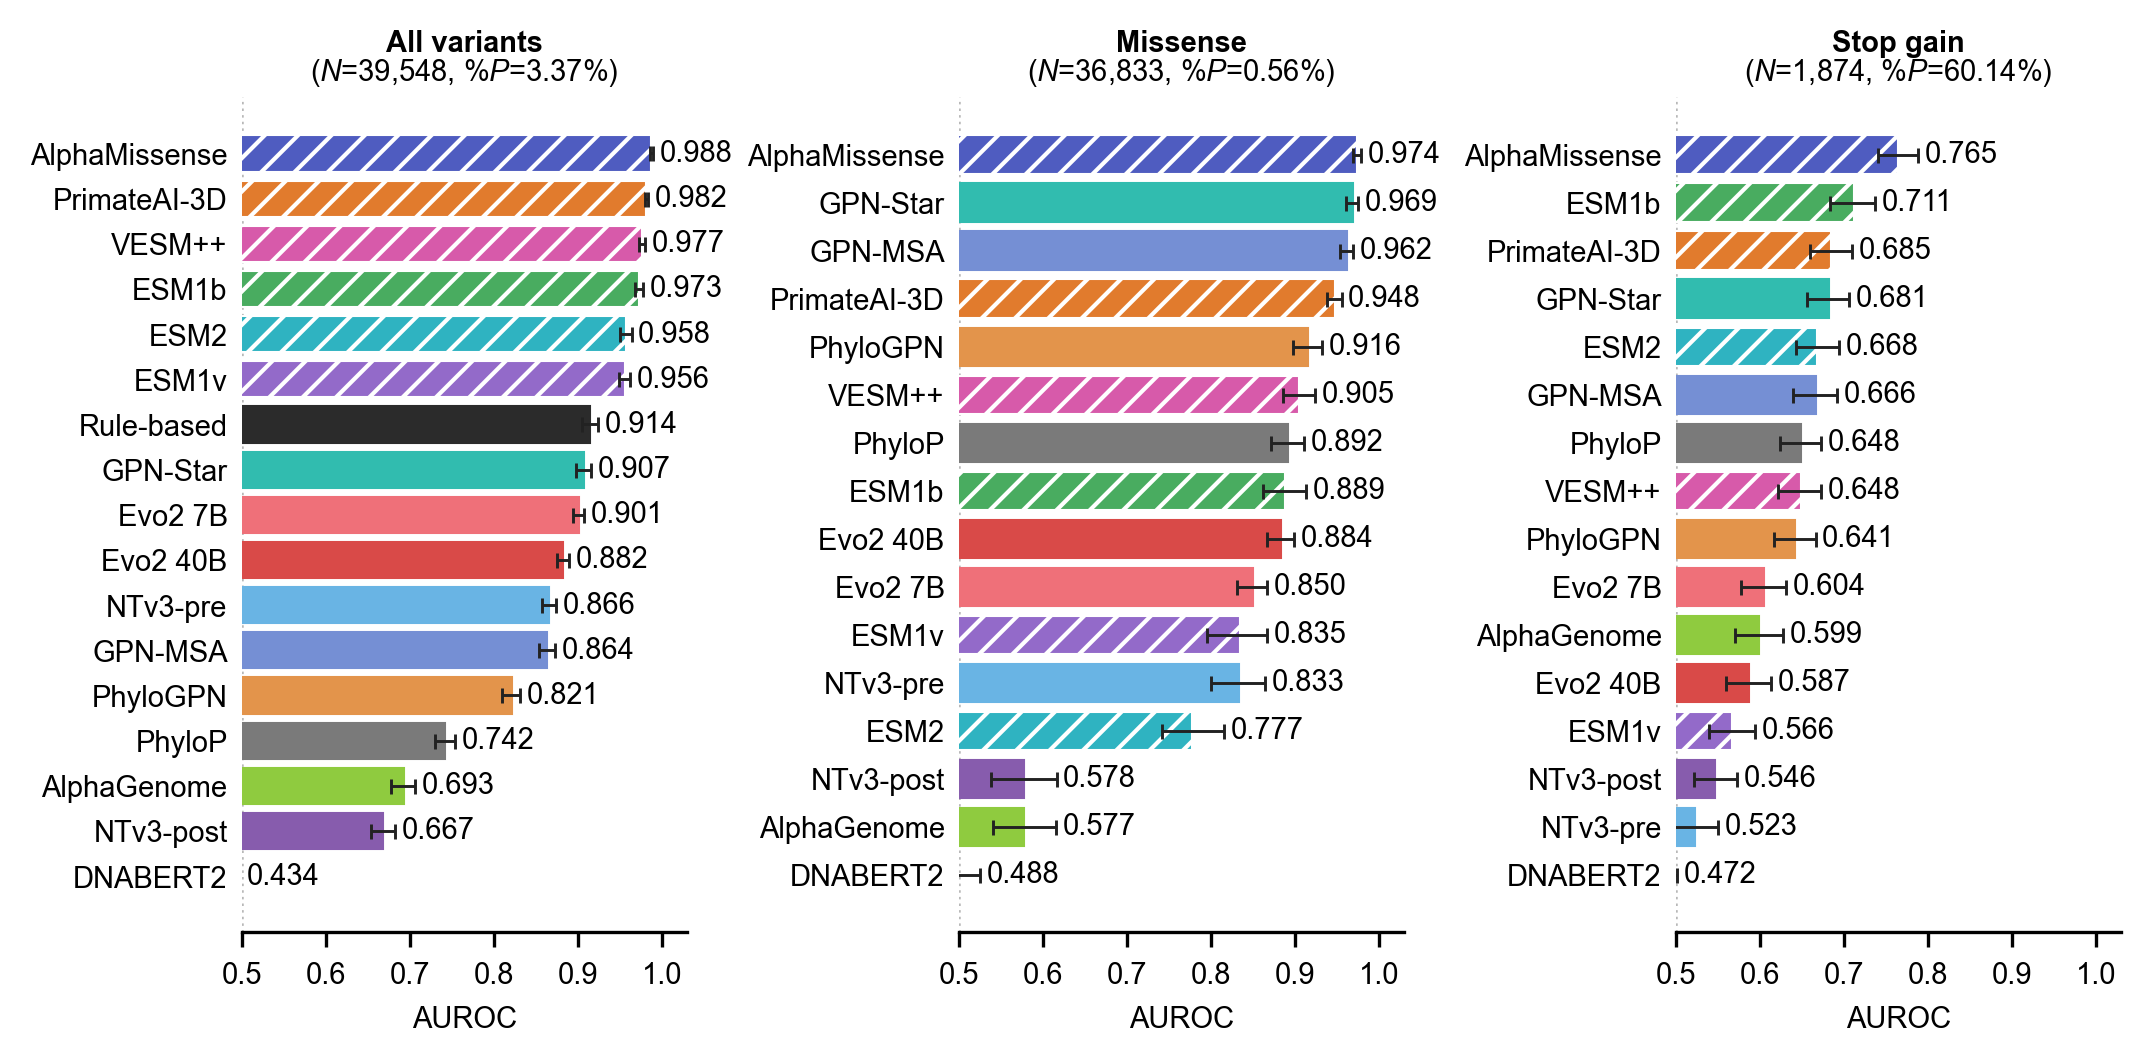

In [4]:
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Arial",
                     "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"})
# Final three-panel COSMIC figure from the frozen AUROC table.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "Arial", "font.size": 7})
FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
COSMIC_DIR = Path("cosmic")
table = pd.read_csv(COSMIC_DIR / "cosmic_auc_result.csv")
ci_low_table = pd.read_csv(COSMIC_DIR / "cosmic_auc_result_ci_low.csv")
ci_high_table = pd.read_csv(COSMIC_DIR / "cosmic_auc_result_ci_high.csv")

rename = {
    "PhyloP": "PhyloP", "Evo2_40b_Var_minus_Ref": "Evo2 40B",
    "Evo2_7b_Var_minus_Ref": "Evo2 7B", "AlphaGenome_raw_abs": "AlphaGenome",
    "GPN_MSA_score": "GPN-MSA", "PhyloGPN": "PhyloGPN", "gpnstar_v_llr": "GPN-Star",
    "DB2": "DNABERT2",
    "ntv3_pre_position_llr": "NTv3-pre", "ntv3_post_log2fc_max": "NTv3-post",
    "ESM1b_score": "ESM1b", "ESM1v-1_score": "ESM1v", "ESM2_score": "ESM2",
    "vesm_score": "VESM++",
    "am_score": "AlphaMissense", "pai_score": "PrimateAI-3D", "Rule_based": "Rule-based",
}
palette = {
    "Evo2 7B": "#EF7079", "Evo2 40B": "#D94A48", "DNABERT2": "#9F3C51",
    "NTv3-pre": "#69B4E4", "PhyloP": "#7A7A7A", "GPN-MSA": "#758FD4",
    "PhyloGPN": "#E3944B", "AlphaGenome": "#8FCB3F", "ESM1b": "#49AC60",
    "ESM1v": "#936AC9", "ESM2": "#2FB3C1", "PrimateAI-3D": "#E17B2D",
    "AlphaMissense": "#4F5CC0", "Rule-based": "#2B2B2B",
    # Restored with the 17-predictor score matrix; colours match Figure 1.
    "GPN-Star": "#31BCAF", "VESM++": "#D75AAA", "NTv3-post": "#875CAD",
}
protein_models = {"ESM1b", "ESM1v", "ESM2", "VESM++", "AlphaMissense", "PrimateAI-3D"}
panels = [("Overall", "All variants"), ("group: Missense", "Missense"), ("group: Stop gain", "Stop gain")]

model_rows = table[~table["Unnamed: 0"].isin(["#Variants", "p%"])]
ci_low_rows = ci_low_table.set_index("Unnamed: 0")
ci_high_rows = ci_high_table.set_index("Unnamed: 0")
n_row = table[table["Unnamed: 0"] == "#Variants"].iloc[0]
p_row = table[table["Unnamed: 0"] == "p%"].iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(180 / 25.4, 88 / 25.4), dpi=300)
for axis, (column, display_name) in zip(axes, panels):
    values = model_rows[["Unnamed: 0", column]].dropna().copy()
    values["model"] = values["Unnamed: 0"].map(rename)
    values = values.dropna(subset=["model"]).sort_values(column)
    for y, row in enumerate(values.itertuples()):
        model = row.model
        score = float(values.iloc[y][column])
        color = palette[model]
        hatch = "///" if model in protein_models else None
        axis.barh(y, score, color=color, hatch=hatch, edgecolor="white" if hatch else color,
                  linewidth=0.5, zorder=1)
        raw_key = row._1
        ci_low = pd.to_numeric(pd.Series([ci_low_rows.at[raw_key, column]]), errors="coerce").iloc[0]
        ci_high = pd.to_numeric(pd.Series([ci_high_rows.at[raw_key, column]]), errors="coerce").iloc[0]
        anchor = score
        if pd.notna(ci_low) and pd.notna(ci_high) and ci_high >= ci_low:
            axis.errorbar(score, y, xerr=[[score - ci_low], [ci_high - score]], fmt="none",
                          ecolor="#222222", elinewidth=0.7, capsize=1.8, capthick=0.7, zorder=3)
            anchor = max(score, ci_high)
        axis.text(max(anchor + 0.008, 0.505), y, f"{score:.3f}", va="center", ha="left", fontsize=7.0)
    axis.set_yticks(range(len(values)), values["model"], fontsize=7.0)
    # Author Checklist row 32 allows bold only in headings, so the subgroup name stays bold
    # while the N and %P line beneath it is set at normal weight. Row 33 requires single-letter
    # scalar variables to be italic, hence $N$ and $P$; multi-letter names such as AUROC and
    # AUPRC are set roman. Mathtext is bound to Arial so the italic stays in the same family.
    axis.set_title(display_name, fontsize=7.0,
                   fontweight="bold", pad=2 + 7.0 + 2)
    axis.annotate(
        f"($N$={int(float(n_row[column])):,}, %$P$={float(p_row[column]):.2f}%)",
        xy=(0.5, 1.0), xycoords="axes fraction", xytext=(0, 2),
        textcoords="offset points", ha="center", va="bottom",
        fontsize=7.0,
    )
    axis.set_xlim(0.5, 1.03)
    axis.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    axis.set_xlabel("AUROC", fontsize=7.0)
    axis.axvline(0.5, color="#B8B8B8", linewidth=0.6, linestyle=":", zorder=0)
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.tick_params(axis="x", labelsize=7.0)
    axis.tick_params(axis="y", length=0)

fig.tight_layout(pad=0.6)
for extension in ("svg", "pdf", "png"):
    fig.savefig(FIGURE_DIR / f"figure_s5.{extension}", dpi=300, facecolor="white")
    fig.savefig(COSMIC_DIR / f"COSMIC_Figure.{extension}", dpi=300, facecolor="white")
plt.show()


## 4. (Optional) Single overall panel

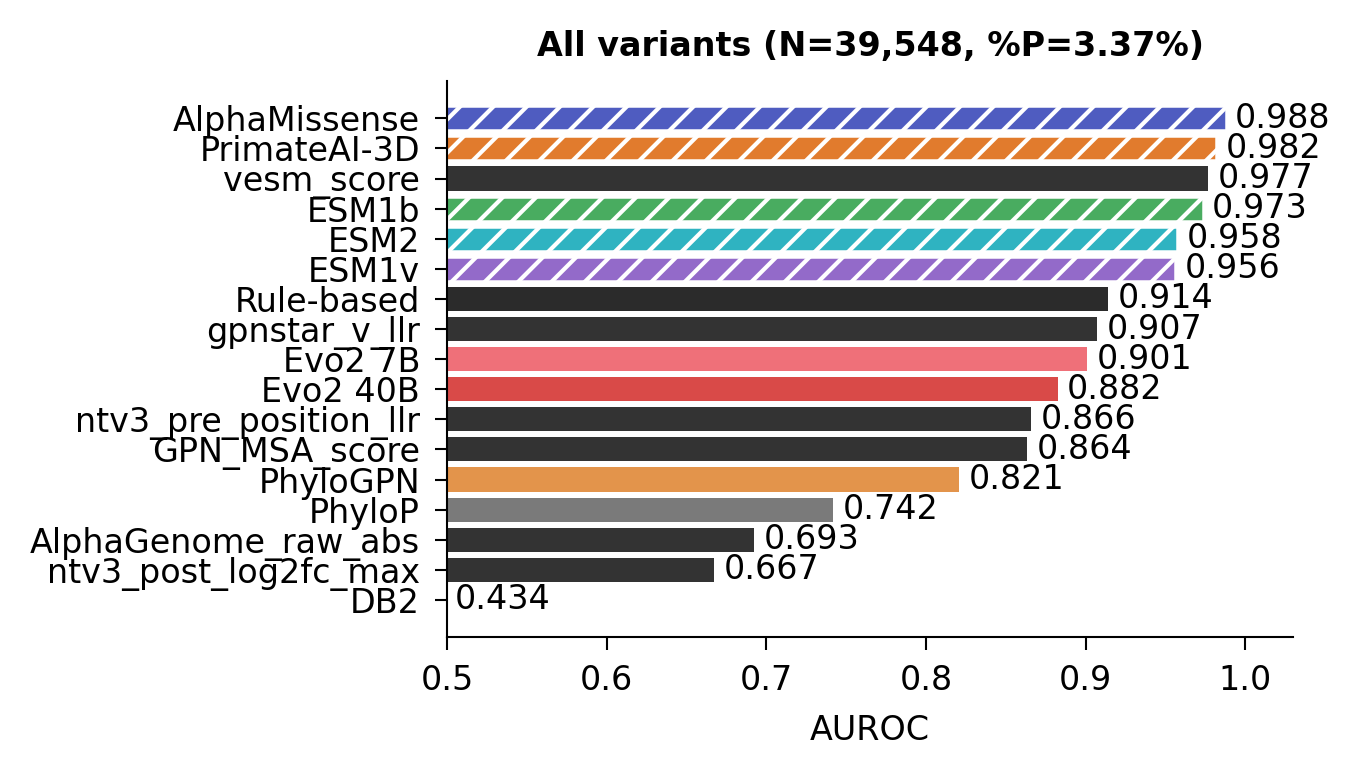

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 2.6), dpi=300)
draw_one_panel(ax, "Overall", "All variants", show_xlabel=True, show_numbers=True)
plt.tight_layout()
plt.savefig(COSMIC_DIR / "COSMIC_Figure_overall.pdf", format="pdf", bbox_inches="tight")
plt.show()

